# Initiation Validation Figures

ROC curves and AUC grid from the validation results written by `run.py` (`validation/` in the output directory).

Run `python run.py <settings file>` with `validation: run: true` first.

In [2]:
# Put This Environment's DLLs First on PATH (VS Code may start the kernel
# without conda activation, which can crash plotting on Windows)
import os, sys
os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

%matplotlib inline
sys.path.insert(0, "..")   # repo root, so 'model' can be imported
import model  # noqa: F401  (hides the standalone GDAL)

# Settings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

settings_file = "../settings/example_POW_NHESS.yaml"   # same settings file used for run.py

with open(settings_file) as f:
    cfg = yaml.safe_load(f)

# Output paths in the settings file are relative to the repo root
out_dir = Path(cfg["paths"]["output_directory"])
if not out_dir.is_absolute():
    out_dir = Path("..") / out_dir
val_dir = out_dir / "validation"

summary = pd.read_csv(val_dir / "summary.csv")
roc = pd.read_csv(val_dir / "roc_curves_draw1.csv")
summary

,depth,saturation,depth_option,saturation_option,reference,AUC_mean,AUC_min,AUC_max,TPR_FS1_pct,FPR_FS1_pct,FPR_FS1_min,FPR_FS1_max,SteepAreaFS1_pct,AreaAtRefHitRate_pct
0,Modeled,Uniform 0.5,modeled,0.5,False,0.837524,0.833641,0.841857,9.814964,0.942,0.68,1.18,0.930036,0.635306
1,0.5 m,Uniform 0.5,0.5,0.5,False,0.769467,0.764390,0.775451,0.000000,0.000,0.00,0.00,0.000000,1.636886
2,1.0 m,Uniform 0.5,1.0,0.5,False,0.765489,0.760509,0.771215,0.884956,0.368,0.18,0.54,0.348790,1.613034
3,1.5 m,Uniform 0.5,1.5,0.5,False,0.762774,0.757834,0.768357,13.837490,3.490,3.18,3.94,3.462347,1.616743
4,Modeled,TWI-based,modeled,modeled,True,0.854317,0.849507,0.857667,7.481899,0.576,0.32,0.74,0.551541,0.549079
5,0.5 m,TWI-based,0.5,modeled,False,0.784622,0.779820,0.789773,0.000000,0.000,0.00,0.00,0.000000,1.323476
6,1.0 m,TWI-based,1.0,modeled,False,0.792483,0.787600,0.797140,0.402253,0.189,0.04,0.34,0.166544,1.372580
7,1.5 m,TWI-based,1.5,modeled,False,0.797319,0.792377,0.801794,11.343524,2.165,1.88,2.52,2.146213,1.372834
8,Modeled,Uniform 1.0,modeled,1.0,False,0.840089,0.836031,0.844584,28.801287,4.119,3.48,4.66,4.186686,0.674841
9,0.5 m,Uniform 1.0,0.5,1.0,False,0.768870,0.763781,0.774764,0.000000,0.000,0.00,0.00,0.000000,1.610781


In [3]:
# Labels, Colors, and Line Styles

v = cfg["validation"]
depth_opts = list(v["depth_options"])
sat_opts = list(v["saturation_options"])

def num(x):
    t = f"{float(x):g}"
    return t if "." in t or "e" in t else t + ".0"

def depth_legend(o):
    return "Modeled colluvium" if o == "modeled" else f"{num(o)} m uniform"

def sat_legend(o):
    return "TWI (median)" if o == "modeled" else ("saturated" if o == 1 else f"$m_w$ = {num(o)}")

# Colluvium depth colors: modeled = blue; uniform depths = light to dark orange
oranges = ["#f29a6e", "#d4561c", "#8a3510", "#5c2309"]
uniform = [o for o in depth_opts if o != "modeled"]
depth_col = {o: ("#2a78d6" if o == "modeled" else oranges[uniform.index(o) % len(oranges)])
             for o in depth_opts}

# Saturation line styles: dotted, solid, dashed, dash-dot
styles = [":", "-", "--", "-."]
sat_ls = {o: styles[i % len(styles)] for i, o in enumerate(sat_opts)}
# TWI-based saturation always solid (as in the paper figure)
if "modeled" in sat_ls:
    other = [o for o in sat_opts if o != "modeled"]
    rest = [s for s in styles if s != "-"]
    sat_ls = {o: ("-" if o == "modeled" else rest[other.index(o) % len(rest)]) for o in sat_opts}

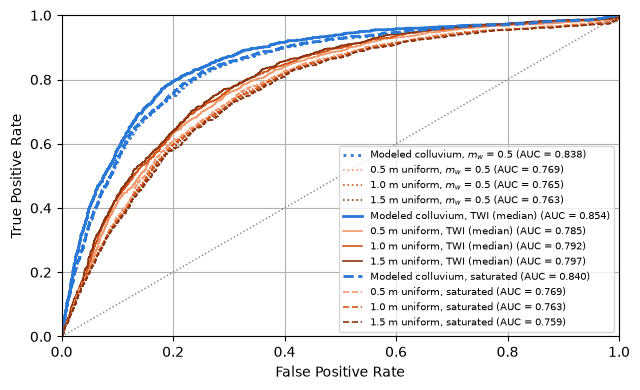

In [4]:
# ROC Curves for All Models (First Background Draw)

fig_w, fig_h = 6.5, 4.0   # inches (3.5: single column; 7: full page)
fig, ax = plt.subplots(figsize=(fig_w, fig_h))

for s in sat_opts:
    for d in depth_opts:
        row = summary[(summary.depth_option.astype(str) == str(d)) &
                      (summary.saturation_option.astype(str) == str(s))].iloc[0]
        curve = roc[(roc.depth == row.depth) & (roc.saturation == row.saturation)]
        ax.plot(curve.fpr, curve.tpr, sat_ls[s], color=depth_col[d],
                linewidth=1.2 + 0.8 * (d == "modeled"),
                label=f"{depth_legend(d)}, {sat_legend(s)} (AUC = {row.AUC_mean:.3f})")

ax.plot([0, 1], [0, 1], ":", color="0.5", linewidth=1)   # random guessing
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="False Positive Rate", ylabel="True Positive Rate")
ax.grid(True)
ax.legend(loc="lower right", fontsize=7)
fig.tight_layout()
fig.savefig(val_dir / "roc_curves.png", dpi=300)
fig.savefig(val_dir / "roc_curves.pdf")
plt.show()

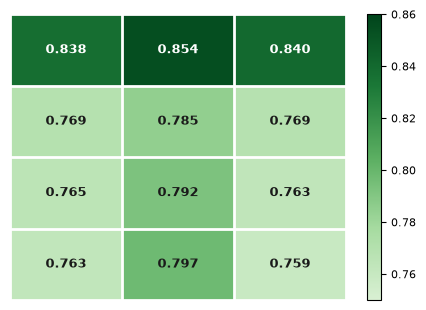

In [5]:
# AUC Grid (Rows: Colluvium Depth, Columns: Saturation)

fig_w_b, fig_h_b = 4.5, 3.2
show_axis_labels = False   # True: show row/column names; False: add labels later
show_cell_values = True

grid = np.array([[summary[(summary.depth_option.astype(str) == str(d)) &
                          (summary.saturation_option.astype(str) == str(s))].AUC_mean.iloc[0]
                  for s in sat_opts] for d in depth_opts])

clim = (np.floor(100 * grid.min()) / 100, np.ceil(100 * grid.max()) / 100)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list(
    "auc", ["#d9f0d3", "#a6dba0", "#5aae61", "#1b7837", "#00441b"])

fig, ax = plt.subplots(figsize=(fig_w_b, fig_h_b))
im = ax.imshow(grid, cmap=cmap, vmin=clim[0], vmax=clim[1], aspect="auto")

# White gridlines between cells
for i in np.arange(-0.5, len(sat_opts)):
    ax.axvline(i, color="w", linewidth=2)
for i in np.arange(-0.5, len(depth_opts)):
    ax.axhline(i, color="w", linewidth=2)

if show_cell_values:
    for di in range(len(depth_opts)):
        for si in range(len(sat_opts)):
            frac = (grid[di, si] - clim[0]) / (clim[1] - clim[0])
            ax.text(si, di, f"{grid[di, si]:.3f}", ha="center", va="center", fontsize=9,
                    fontweight="bold", color="w" if frac > 0.55 else "0.1")

ax.xaxis.tick_top()
ax.tick_params(length=0, labelsize=8)
if show_axis_labels:
    ax.set_xticks(range(len(sat_opts)), [sat_legend(s) for s in sat_opts])
    ax.set_yticks(range(len(depth_opts)), [depth_legend(d) for d in depth_opts])
    ax.set_xlabel("Saturation"); ax.xaxis.set_label_position("top")
    ax.set_ylabel("Colluvium Depth")
else:
    ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
cb = fig.colorbar(im, ax=ax)
cb.ax.tick_params(labelsize=8)
if show_axis_labels:
    cb.set_label("AUC")
fig.tight_layout()
fig.savefig(val_dir / "auc_grid.png", dpi=300)
fig.savefig(val_dir / "auc_grid.pdf")
plt.show()

In [6]:
# Values for Figure Caption

for _, r in summary.iterrows():
    print(f"{r.depth:<10} {r.saturation:<14} AUC = {r.AUC_mean:.3f} ({r.AUC_min:.3f}-{r.AUC_max:.3f})")

Modeled    Uniform 0.5    AUC = 0.838 (0.834-0.842)
0.5 m      Uniform 0.5    AUC = 0.769 (0.764-0.775)
1.0 m      Uniform 0.5    AUC = 0.765 (0.761-0.771)
1.5 m      Uniform 0.5    AUC = 0.763 (0.758-0.768)
Modeled    TWI-based      AUC = 0.854 (0.850-0.858)
0.5 m      TWI-based      AUC = 0.785 (0.780-0.790)
1.0 m      TWI-based      AUC = 0.792 (0.788-0.797)
1.5 m      TWI-based      AUC = 0.797 (0.792-0.802)
Modeled    Uniform 1.0    AUC = 0.840 (0.836-0.845)
0.5 m      Uniform 1.0    AUC = 0.769 (0.764-0.775)
1.0 m      Uniform 1.0    AUC = 0.763 (0.758-0.769)
1.5 m      Uniform 1.0    AUC = 0.759 (0.754-0.764)
